# Linear Regression: Baseline and Two Improvements

This experiment predicts the numerical disease-progression score one year after baseline using the public diabetes dataset distributed with scikit-learn. It contains 442 patient records and 10 predictors, including age, BMI, blood pressure, and six blood measurements. This is a regression task because the target is a number.

The comparison starts with ordinary linear regression using all 10 predictors, then tries ridge regression and degree-2 polynomial features with ridge regression.

Dataset: [scikit-learn diabetes dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset). The dataset is bundled with scikit-learn, so no separate download is required.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

SEED = 42
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__}")
print(f"NumPy {np.__version__} | pandas {pd.__version__}")

Python 3.12.14 | scikit-learn 1.8.0
NumPy 2.3.5 | pandas 2.2.3


## Data and evaluation

I used an 80/20 split: 353 records for training and 89 for the final test. A fixed random seed makes the split reproducible.

RMSE (root mean squared error) measures prediction error in the same units as the target score. Lower is better, and large mistakes receive extra weight. RMSE is not an accuracy percentage.

Within the training set, I used five-fold cross-validation: train on four groups and validate on the fifth, rotating until every group has been used for validation. All models use the same folds. Ridge settings are chosen by the lowest average validation RMSE. Only after choosing the settings are all three models evaluated on the same test set.

I load raw predictors with `scaled=False`. Each pipeline learns scaling from its training data only, including inside each validation fold. This prevents information from the validation or test data from leaking into preprocessing. Scaling is also included in the baseline, so it is not an extra advantage given only to the improved models.

In [2]:
X, y = load_diabetes(return_X_y=True, as_frame=True, scaled=False)
assert X.shape == (442, 10)
assert X.notna().all().all() and y.notna().all()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Training records: {len(X_train)} | Test records: {len(X_test)}")
print("Predictors:", ", ".join(X.columns))
print("Missing values:", int(X.isna().sum().sum() + y.isna().sum()))
print(f"Training correlation between s1 and s2: {X_train['s1'].corr(X_train['s2']):.3f}")

Training records: 353 | Test records: 89
Predictors: age, sex, bmi, bp, s1, s2, s3, s4, s5, s6
Missing values: 0
Training correlation between s1 and s2: 0.891


## Baseline: ordinary linear regression

The baseline fits one coefficient, or weight, for each original predictor. It minimizes the sum of squared errors on the training records. It has no penalty limiting the size of its coefficients.

In [3]:
baseline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression())
])
baseline_cv = -cross_val_score(
    baseline, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error"
)
baseline.fit(X_train, y_train)
print(f"Baseline validation RMSE: {baseline_cv.mean():.4f}")

Baseline validation RMSE: 55.3946


## Improvement 1: ridge regression

Ridge adds a penalty for large coefficients. This is called regularization: it discourages the model from relying too heavily on patterns that may be noise. The parameter `alpha` controls the strength of that penalty. I compare 15 values from 0.001 to 10,000 using only the training folds.

In [4]:
alphas = np.logspace(-3, 4, 15)
ridge_search = GridSearchCV(
    Pipeline([
        ("scale", StandardScaler()),
        ("model", Ridge())
    ]),
    param_grid={"model__alpha": alphas},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1
)
ridge_search.fit(X_train, y_train)
print("Selected alpha:", ridge_search.best_params_["model__alpha"])
print(f"Selected validation RMSE: {-ridge_search.best_score_:.4f}")

Selected alpha: 1.0
Selected validation RMSE: 55.3742


## Improvement 2: polynomial features with ridge

Degree-2 polynomial features add squared terms, such as BMI², and interactions, such as BMI × blood pressure. These let the prediction curve and let the effect of one variable depend on another. The expansion produces 65 terms from the original 10 predictors.

I keep the degree fixed at 2 and tune ridge's penalty on the same alpha grid. Ridge helps control the extra complexity. This remains linear in its fitted coefficients, although its relationship with the original inputs can be curved.

In [5]:
polynomial_search = GridSearchCV(
    Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scale", StandardScaler()),
        ("model", Ridge())
    ]),
    param_grid={"model__alpha": alphas},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1
)
polynomial_search.fit(X_train, y_train)
print("Selected alpha:", polynomial_search.best_params_["model__alpha"])
print("Expanded terms:", polynomial_search.best_estimator_.named_steps["poly"].n_output_features_)
print(f"Selected validation RMSE: {-polynomial_search.best_score_:.4f}")

Selected alpha: 10.0
Expanded terms: 65
Selected validation RMSE: 55.1785


## Results on the reserved test set

All hyperparameters are now fixed. Each model is refitted on all 353 training records and evaluated on the same 89 reserved records. GridSearchCV performs the refit automatically.

Percentage reduction in test RMSE = 100 × (baseline test RMSE − model test RMSE) / baseline test RMSE.

The validation scores below are the means of five fold RMSEs. For tuned models, these scores were used to choose alpha, so they are selection scores rather than independent performance estimates. The test scores provide the separate check.

In [6]:
models = {
    "Linear regression": baseline,
    "Ridge": ridge_search.best_estimator_,
    "Polynomial + ridge": polynomial_search.best_estimator_
}
cv_means = [baseline_cv.mean(), -ridge_search.best_score_, -polynomial_search.best_score_]
cv_sds = [
    baseline_cv.std(),
    ridge_search.cv_results_["std_test_score"][ridge_search.best_index_],
    polynomial_search.cv_results_["std_test_score"][polynomial_search.best_index_]
]
rows = []
test_predictions = {}
for (name, model), cv_mean, cv_sd in zip(models.items(), cv_means, cv_sds):
    prediction = model.predict(X_test)
    test_predictions[name] = prediction
    rows.append({
        "Model": name,
        "Train RMSE": root_mean_squared_error(y_train, model.predict(X_train)),
        "CV RMSE": cv_mean,
        "CV fold SD": cv_sd,
        "Test RMSE": root_mean_squared_error(y_test, prediction),
        "Test MAE": mean_absolute_error(y_test, prediction),
        "Test R2": r2_score(y_test, prediction)
    })
results = pd.DataFrame(rows)
base_rmse = results.loc[0, "Test RMSE"]
results["RMSE reduction %"] = 100 * (base_rmse - results["Test RMSE"]) / base_rmse
print(results.round(4).to_string(index=False))

# Audit checks for the fixed comparison and independently computed metric.
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(X)
assert np.isclose(base_rmse, np.sqrt(np.mean((y_test - test_predictions["Linear regression"])**2)))
assert ridge_search.best_estimator_.named_steps["scale"].n_samples_seen_ == len(X_train)
assert polynomial_search.best_estimator_.named_steps["scale"].n_samples_seen_ == len(X_train)
selected_model = results.loc[results["CV RMSE"].idxmin(), "Model"]
print("\nModel selected by training cross-validation:", selected_model)

             Model  Train RMSE  CV RMSE  CV fold SD  Test RMSE  Test MAE  Test R2  RMSE reduction %
 Linear regression     53.5588  55.3946      2.3615    53.8534   42.7941   0.4526            0.0000
             Ridge     53.5751  55.3742      2.3732    53.7775   42.8120   0.4541            0.1411
Polynomial + ridge     52.2650  55.1785      2.3403    52.6663   41.7544   0.4765            2.2045

Model selected by training cross-validation: Polynomial + ridge


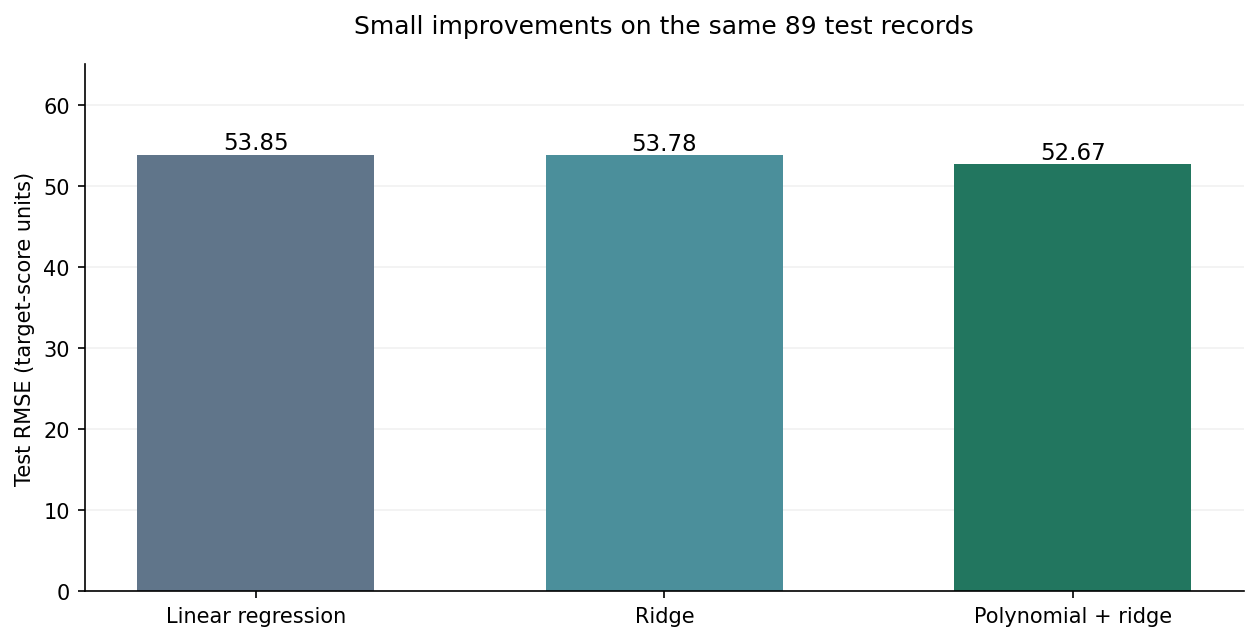

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
labels = ["Linear regression", "Ridge", "Polynomial + ridge"]
values = results["Test RMSE"].to_numpy()
bars = ax.bar(labels, values, color=["#60758a", "#4b8f9b", "#22765f"], width=0.58)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.7, f"{value:.2f}",
            ha="center", fontsize=11)
ax.set_ylim(0, 65)
ax.set_ylabel("Test RMSE (target-score units)")
ax.set_title("Small improvements on the same 89 test records", pad=15)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## Explanation

The baseline test RMSE was 53.85 target-score units. Ridge reduced it to 53.78, a reduction of 0.14%. Polynomial features with ridge reduced it to 52.67, a reduction of 2.20%. These percentages describe error reduction, not prediction accuracy.

**What likely explains ridge's result?** Some predictors overlap strongly: s1 and s2 have a training correlation of 0.891. Overlapping inputs can make ordinary regression's weights unstable. Ridge shrinks those weights, which can make predictions less sensitive to noise. Here the gain is very small, so the evidence for a useful improvement is weak.

**What likely explains the polynomial result?** The squared terms and interactions can represent relationships the original straight-line model misses. Its lower validation and test RMSE are consistent with some useful additional flexibility. The penalty limits the new coefficients and helps control overfitting. These are plausible explanations, not proof of which individual terms caused the gain; that would require further controlled comparisons.

**How convincing is the improvement?** The polynomial model has the lowest cross-validation mean (55.18 versus 55.39) and the lowest test RMSE. However, the validation difference is only 0.22 units, and the test improvement is just 1.19 units. With only 89 test records, these are modest findings from one split, not evidence of a reliably large gain. The fold standard deviations describe variation across validation folds; they are not confidence intervals. More independent evaluation would help establish how stable the advantage is.

I would keep the polynomial-plus-ridge model as the best candidate in this experiment because it was selected using training cross-validation and also performed best on the held-out test set. The ordinary linear model remains a reasonable simpler option given the small difference.